# Conformal Pillbox Geometry – Visual Check

Dieses Notebook lädt die vorhandene WAKIS-Pillbox-Geometrie und ergänzt ein drittes STL-Volumen im oberen Bereich der Cavity.

- `cavity`: Vakuum (`normal`)
- `shell`: PEC
- `dielectric`: $\varepsilon_r=4$, `normal`

Damit enthält ein zentraler Querschnitt sowohl **normal–PEC**- als auch **normal–normal**-Übergänge. Anschließend wird die neue Conformal-Edge-Slice-Plotfunktion aufgerufen.


In [1]:
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import pyvista as pv

from wakis import GridFIT3D, SolverFIT3D

## Repository und Standard-Pillbox-STLs

Das Notebook sucht automatisch den WAKIS-Repository-Root und verwendet die bereits vorhandenen Test-STLs.


In [2]:
cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

cavity_mesh = pv.read(cavity_path).triangulate().clean()
shell_mesh = pv.read(shell_path).triangulate().clean()

## Zusätzliches Dielektrik-Volumen

Der Block liegt vollständig im oberen/zentralen Bereich der Cavity. Dadurch vermeiden wir für diesen ersten Visualisierungstest unnötige koinzidente Flächen mit der PEC-Shell.


In [3]:
xmin, xmax, ymin, ymax, zmin, zmax = cavity_mesh.bounds

dielectric_bounds = (
    xmin + 0.25 * (xmax - xmin),
    xmax - 0.25 * (xmax - xmin),
    0.5 * (ymin + ymax),
    ymin + 0.72 * (ymax - ymin),
    zmin + 0.15 * (zmax - zmin),
    zmax - 0.15 * (zmax - zmin),
)

dielectric_mesh = pv.Box(bounds=dielectric_bounds).triangulate()

dielectric_path = Path("pillbox_upper_dielectric.stl")
dielectric_mesh.save(dielectric_path)

## Conformal Grid und Solver

Wichtig ist die Reihenfolge der Solids: `dielectric` steht zuletzt und hat damit in seinem Volumen Priorität gegenüber der überlappenden `cavity`-Region.


In [4]:
stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
    "dielectric": str(dielectric_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
    "dielectric": [4.0, 1.0, 0.0],
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
    "dielectric": "normal",
}

all_geometry = cavity_mesh + shell_mesh
xmin, xmax, ymin, ymax, zmin, zmax = all_geometry.bounds

# Moderate resolution: coarse enough to clearly see individual clipped edges.
Nx, Ny, Nz = 20, 20, 30

grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    geometry_mode="conformal",
    stl_method="interior_points",
    verbose=1,
)

solver = SolverFIT3D(
    grid,
    bg=[1.0, 1.0, 0.0],
    use_stl=True,
    verbose=1,
)

Generating grid with 12000 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 2931 primal points, 2655 cell centers, and 2885 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 1347 primal points, 618 cell centers, and 1448 dual points marked inside the solid.
 * Marking grid points inside STL solid 'dielectric'...
    * STL solid dielectric: 662 primal points, 466 cell centers, and 640 dual points marked inside the solid.
    * primal x-edges: 1474 geometric hits, 1474 crossings, 0 contacts, 325 with multiple crossing positions
    * primal y-edges: 1665 geometric hits, 1665 crossings, 0 contacts, 355 with multiple crossing positions
    * primal z-edges: 1130 geometric hits, 1130 crossings, 0 contacts, 362 with multiple crossing positions
    * dual x-edges: 1420 geometric hits, 1420 crossings, 0 contacts, 298 with multiple crossing positions
    * dual y-edges: 

/Users/hannesschreiber/Documents/WAKIS/wakis/gridFIT3D.py:3580: UserWarning: Conformal geometry diagnostics:
306 endpoint interface edges have no geometric crossing and will not receive a conformal correction.
748 edges contain geometric crossings that are hidden from endpoint topology and are ignored by the current conformal discretization.
2050 edges contain multiple crossing positions. 1934 of these are currently used by the conformal discretization; one representative crossing is selected on each edge.
  self._warn_interface_diagnostics()


    * primal x-faces: 2449 candidates, 1515 segments, 561 resolved splits
    * primal y-faces: 2278 candidates, 1460 segments, 884 resolved splits
    * primal z-faces: 2702 candidates, 1789 segments, 898 resolved splits
    * dual x-faces: 2428 candidates, 1640 segments, 591 resolved splits
    * dual y-faces: 2278 candidates, 1516 segments, 922 resolved splits
    * dual z-faces: 2677 candidates, 1961 segments, 1041 resolved splits
Total grid initialization time: 9.849802017211914 s
Initializing Electromagnetic solver...
Assembling operator matrices...
Applying boundary conditions...
Adding material tensors...
Calculating maximal stable timestep...
Pre-computing...
Total solver initialization time: 1.5602757930755615 s


## Conformal Edge Slice

Der mittlere `z`-Slice zeigt die x-y-Ebene der Pillbox. Dort sollten sichtbar sein:

- außen die gekürzten Kanten an der PEC-Shell,
- innen vollständige Vakuum-Kanten,
- im oberen Bereich die Vakuum–Dielektrikum-Grenze,
- die tatsächlichen STL-Schnittlinien als dünne Referenz.


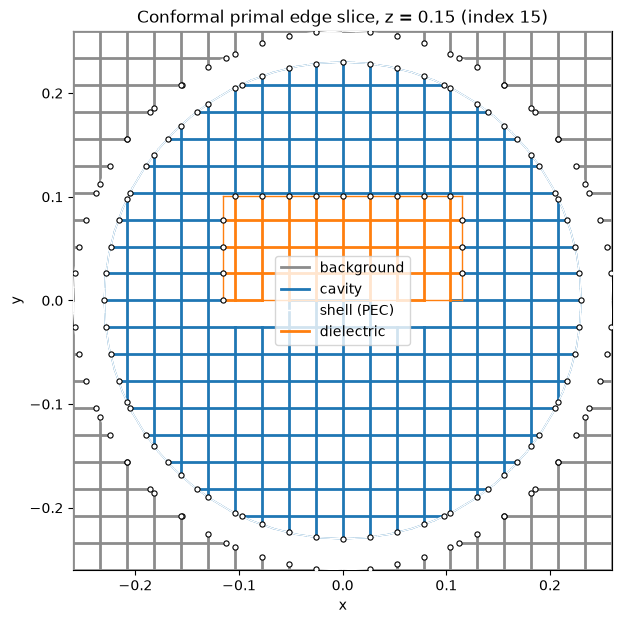

In [5]:
slice_index = Nz // 2

ax = solver.plot_conformal_primal_edge_slice(
    normal="z",
    index=slice_index,
    show_full_grid=False,
    show_stl=True,
    show_intersection_marker=True,
)

plt.show()

## Optional: anderer Querschnitt

Falls du anschließend die Geometrie aus einer zweiten Richtung prüfen willst, kannst du z. B. einen mittleren `y`-Slice verwenden.


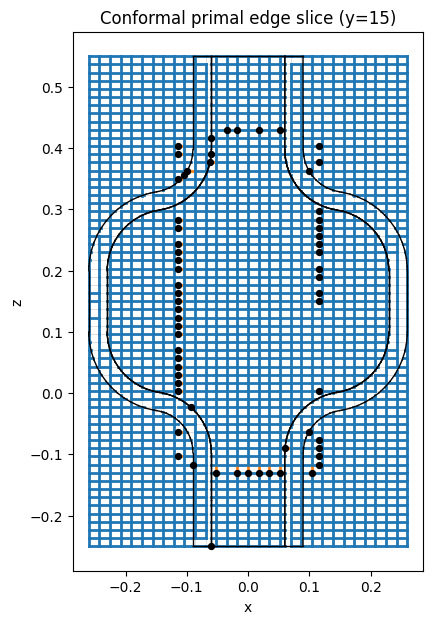

In [6]:
# Optional
ax = solver.plot_conformal_primal_edge_slice(
    normal="y",
    index=Ny // 2,
    show_full_grid=True,
    show_stl=True,
    show_intersection_marker=True,
    split_normal_normal=True,
)
plt.show()